In [2]:
"""Funciones de apoyo para árboles de regresión y de clasificación (primer
taller de árboles e interpretabilidad).

Uso, con este archivo en la carpeta de trabajo:

    from functions_p1 import (rss, gini, evaluar_cortes, mejor_corte,
                              graficar_cortes, graficar_respuesta,
                              graficar_arbol, tabla_hojas, predecir_con_ruta,
                              graficar_regiones, errores_regresion,
                              curva_profundidad, matriz_confusion,
                              metricas_clasificacion)

Los árboles se ajustan con scikit-learn (DecisionTreeRegressor y
DecisionTreeClassifier) y se pasan a estas funciones. Las funciones de búsqueda
de cortes repiten a mano lo que hace el árbol en cada nodo. Los datos deben ser
DataFrame y Series de pandas.

    Búsqueda de cortes
    rss                     RSS de un grupo al predecirlo con su media
    gini                    índice de Gini de un grupo
    evaluar_cortes          RSS o Gini ponderado de cada corte admisible de una predictora
    mejor_corte             mejor corte de cada predictora frente a no dividir
    graficar_cortes         criterio de cada corte admisible frente al punto de corte

    Lectura del árbol ajustado
    graficar_respuesta      respuesta frente a cada predictora
    graficar_arbol          dibujo del árbol con plot_tree
    tabla_hojas             regla, tamaño y predicción de cada hoja
    predecir_con_ruta       hoja, regla y predicción de observaciones nuevas
    graficar_regiones       partición del plano de dos predictoras

    Evaluación
    errores_regresion       RSS, MSE y RMSE de entrenamiento y de prueba
    curva_profundidad       error de entrenamiento, validación cruzada y prueba por profundidad
    matriz_confusion        matriz de confusión con la clase positiva al final
    metricas_clasificacion  TCC, tasa de error, sensibilidad y especificidad
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone, is_classifier
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import KFold, cross_validate
from sklearn.tree import plot_tree

SEMILLA = 2026


# ---------------------------------------------------------------------
#                         Funciones auxiliares
# ---------------------------------------------------------------------
def _nombre_error(modelo):
    return "Tasa de error" if is_classifier(modelo) else "MSE"


def _error(modelo, y, pred):
    # MSE en regresión y tasa de error en clasificación.
    if is_classifier(modelo):
        return 1 - accuracy_score(y, pred)
    return mean_squared_error(y, pred)


def _metrica(modelo):
    # Métrica equivalente de scikit-learn (mayor es mejor).
    return "accuracy" if is_classifier(modelo) else "neg_mean_squared_error"


def _a_error(modelo, puntaje):
    # Convierte el puntaje de _metrica en error.
    return 1 - puntaje if is_classifier(modelo) else -puntaje


def _reglas(modelo):
    # Condiciones que llevan desde la raíz hasta cada nodo. scikit-learn envía
    # a la izquierda los valores <= corte y numera a cada hijo después de su padre.
    arbol = modelo.tree_
    nombres = getattr(modelo, "feature_names_in_",
                      [f"X{j}" for j in range(modelo.n_features_in_)])
    reglas = {0: []}
    for nodo in range(arbol.node_count):
        if arbol.children_left[nodo] >= 0:
            v, c = nombres[arbol.feature[nodo]], arbol.threshold[nodo]
            reglas[arbol.children_left[nodo]] = reglas[nodo] + [f"{v} <= {c:g}"]
            reglas[arbol.children_right[nodo]] = reglas[nodo] + [f"{v} > {c:g}"]
    return reglas


# ---------------------------------------------------------------------
#                          Búsqueda de cortes
# ---------------------------------------------------------------------
def rss(y):
    """Suma de cuadrados de los residuales de un grupo al predecirlo con su media."""
    y = np.asarray(y, dtype=float)
    return float(((y - y.mean()) ** 2).sum())


def gini(y):
    """Índice de Gini de un grupo: 1 - sum_k p_k^2, con p_k la proporción de la clase k."""
    p = pd.Series(np.asarray(y)).value_counts(normalize=True)
    return float(1 - (p ** 2).sum())


def evaluar_cortes(x, y, min_hoja=10, criterio="rss"):
    """Evalúa todos los cortes admisibles de la predictora numérica x.

    Los candidatos son los puntos medios entre valores consecutivos distintos de
    x: cualquier otro punto entre ellos deja las mismas observaciones a cada
    lado. Se admiten los cortes que dejan al menos min_hoja observaciones en
    cada grupo; el grupo izquierdo es x < corte.
    criterio="rss" (regresión): RSS de cada grupo y RSS total.
    criterio="gini" (clasificación): Gini de cada grupo y Gini ponderado,
        (n_izq * G_izq + n_der * G_der) / n.
    Devuelve un DataFrame con una fila por corte admisible; la última columna es
    el criterio que se minimiza.
    """
    medida = {"rss": rss, "gini": gini}[criterio]
    x = np.asarray(x, dtype=float)
    y = np.asarray(y)
    valores = np.unique(x)
    filas = []
    for corte in (valores[:-1] + valores[1:]) / 2:
        izq = x < corte
        n_izq, n_der = int(izq.sum()), int((~izq).sum())
        if min(n_izq, n_der) < min_hoja:
            continue
        m_izq, m_der = medida(y[izq]), medida(y[~izq])
        total = (m_izq + m_der if criterio == "rss"
                 else (n_izq * m_izq + n_der * m_der) / len(x))
        filas.append((corte, n_izq, n_der, m_izq, m_der, total))
    columnas = ["corte", "n_izq", "n_der"] + (
        ["RSS_izq", "RSS_der", "RSS_total"] if criterio == "rss"
        else ["Gini_izq", "Gini_der", "Gini_ponderado"])
    return pd.DataFrame(filas, columns=columnas)


def mejor_corte(X, y, min_hoja=10, criterio="rss"):
    """Mejor corte de cada predictora de X, comparado con no dividir.

    Para cada predictora reporta el número de cortes admisibles, el mejor corte
    y su criterio (RSS total o Gini ponderado). La fila "sin dividir" tiene el
    criterio del grupo completo: el RSS al predecir con la media o el Gini.
    Ordenada de menor a mayor criterio: la primera fila es la división que elige
    el árbol en este nodo.
    """
    nombre = "RSS" if criterio == "rss" else "Gini"
    filas = {"sin dividir": {"cortes_admisibles": 0, "mejor_corte": np.nan,
                             nombre: {"rss": rss, "gini": gini}[criterio](y)}}
    for v in X.columns:
        cortes = evaluar_cortes(X[v], y, min_hoja, criterio)
        if cortes.empty:
            continue
        mejor = cortes.iloc[cortes.iloc[:, -1].argmin()]
        filas[v] = {"cortes_admisibles": len(cortes), "mejor_corte": mejor["corte"],
                    nombre: mejor.iloc[-1]}
    return pd.DataFrame.from_dict(filas, orient="index").sort_values(nombre)


def graficar_cortes(X, y, min_hoja=10, criterio="rss"):
    """Grafica, para cada predictora de X, el criterio de cada corte admisible
    (RSS total o Gini ponderado) frente al punto de corte. La línea punteada es
    el criterio sin dividir y la discontinua, el mejor corte de la predictora.
    Devuelve un diccionario {predictora: tabla de evaluar_cortes}.
    """
    tablas = {v: evaluar_cortes(X[v], y, min_hoja, criterio) for v in X.columns}
    sin_dividir = {"rss": rss, "gini": gini}[criterio](y)
    _, ejes = plt.subplots(1, len(tablas), sharey=True, figsize=(5 * len(tablas), 3.8),
                           squeeze=False)
    for ax, (v, t) in zip(ejes[0], tablas.items()):
        criterio_corte = t.iloc[:, -1]
        mejor = t["corte"].iloc[criterio_corte.argmin()]
        ax.plot(t["corte"], criterio_corte, marker="o", markersize=3, linewidth=1.5)
        ax.axhline(sin_dividir, color="gray", linestyle=":")
        ax.axvline(mejor, color="gray", linestyle="--")
        # Rótulos bajo la línea de no dividir, donde la curva casi nunca llega.
        ax.annotate(f"mejor corte: {mejor:g}", (mejor, sin_dividir), xytext=(5, -5),
                    textcoords="offset points", va="top", color="dimgray")
        ax.annotate("sin dividir", (1, sin_dividir), xycoords=("axes fraction", "data"),
                    xytext=(-3, 3), textcoords="offset points", ha="right", color="dimgray")
        ax.set_xlabel(f"Punto de corte en {v}")
    minimo = min(t.iloc[:, -1].min() for t in tablas.values())
    ejes[0][0].set_ylim(top=sin_dividir + 0.08 * (sin_dividir - minimo))
    ejes[0][0].set_ylabel("RSS total" if criterio == "rss" else "Gini ponderado")
    plt.tight_layout()
    plt.show()
    return tablas


# ---------------------------------------------------------------------
#                       Lectura del árbol ajustado
# ---------------------------------------------------------------------
def graficar_respuesta(X, y):
    """Diagrama de dispersión de la respuesta y frente a cada predictora de X."""
    _, ejes = plt.subplots(1, X.shape[1], sharey=True, figsize=(5 * X.shape[1], 3.8),
                           squeeze=False)
    for ax, v in zip(ejes[0], X.columns):
        ax.scatter(X[v], y, s=14, alpha=0.6)
        ax.set_xlabel(v)
    ejes[0][0].set_ylabel(y.name)
    plt.tight_layout()
    plt.show()


def graficar_arbol(modelo, decimales=3):
    """Dibuja el árbol ajustado con plot_tree. En cada nodo aparecen la regla (a
    la izquierda, True, van los valores <= corte), la impureza (squared_error =
    RSS / n, o gini), samples (observaciones de entrenamiento) y value: la media
    de la respuesta o el número de observaciones de cada clase, en el orden de
    modelo.classes_."""
    clases = [str(c) for c in modelo.classes_] if is_classifier(modelo) else None
    # Tamaño según las hojas y la profundidad, para que el texto se lea en árboles pequeños.
    ancho = min(16, max(5, 2.1 * modelo.get_n_leaves()))
    plt.figure(figsize=(ancho, 1.2 * (modelo.get_depth() + 1) + 0.4))
    plot_tree(modelo, feature_names=list(modelo.feature_names_in_), class_names=clases,
              precision=decimales, fontsize=11, rounded=True)
    plt.tight_layout()
    plt.show()


def tabla_hojas(modelo):
    """Una fila por hoja del árbol ajustado: la regla que la define (las
    condiciones desde la raíz), el número de observaciones de entrenamiento y la
    predicción. En regresión la predicción es la media de la respuesta en la
    hoja; en clasificación, la proporción de cada clase y la clase mayoritaria.
    El índice es el número de nodo que devuelve modelo.apply(X).
    """
    arbol = modelo.tree_
    reglas = _reglas(modelo)
    hojas = np.flatnonzero(arbol.children_left < 0)
    tabla = pd.DataFrame({"regla": [" y ".join(reglas[h]) for h in hojas],
                          "n": arbol.n_node_samples[hojas]},
                         index=pd.Index(hojas, name="hoja"))
    valores = arbol.value[hojas, 0, :]
    if is_classifier(modelo):
        proporciones = valores / valores.sum(axis=1, keepdims=True)
        for k, clase in enumerate(modelo.classes_):
            tabla[f"p_{clase}"] = proporciones[:, k]
        tabla["clase"] = modelo.classes_[proporciones.argmax(axis=1)]
    else:
        tabla["prediccion"] = valores[:, 0]
    return tabla


def predecir_con_ruta(modelo, X_nuevos):
    """Predicción de cada fila de X_nuevos junto con la hoja a la que llega y la
    regla que recorre hasta ella: la explicación de la predicción en un árbol.
    Las predictoras que no aparecen en la regla no influyen en esa predicción.
    La observación no se agrega a la hoja: la predicción es la de tabla_hojas.
    """
    hojas = tabla_hojas(modelo)
    return X_nuevos.assign(hoja=modelo.apply(X_nuevos)).join(hojas, on="hoja")


def graficar_regiones(modelo, X, color=None, etiquetas=False):
    """Partición del plano de las dos predictoras de X que define el árbol.

    Cada corte se dibuja solo dentro de la región que divide; los puntos son las
    observaciones de X y cada rectángulo muestra la predicción de su hoja (la
    media en regresión, la clase en clasificación) y su número de observaciones
    de entrenamiento. color: opcional, la respuesta de X para colorear los
    puntos (numérica: escala de un tono; categórica: un color y un marcador por
    clase). etiquetas=True rotula cada punto con su índice en X (útil con pocos
    datos). Devuelve la tabla de tabla_hojas.
    """
    if X.shape[1] != 2:
        raise ValueError("graficar_regiones requiere exactamente dos predictoras.")
    arbol = modelo.tree_
    hojas = tabla_hojas(modelo)
    v1, v2 = X.columns
    ancho, alto = np.ptp(X[v1]), np.ptp(X[v2])
    limites = ((X[v1].min() - 0.04 * ancho, X[v1].max() + 0.04 * ancho),
               (X[v2].min() - 0.04 * alto, X[v2].max() + 0.04 * alto))
    tamano = 40 if len(X) <= 30 else 14
    _, ax = plt.subplots(figsize=(7.5, 4.8))
    if color is None:
        ax.scatter(X[v1], X[v2], s=tamano, color="gray", alpha=0.6)
    elif pd.api.types.is_numeric_dtype(color):
        # Escala de un solo tono que empieza en un azul visible sobre el fondo blanco.
        azules = LinearSegmentedColormap.from_list("azules",
                                                   plt.cm.Blues(np.linspace(0.3, 1, 256)))
        puntos = ax.scatter(X[v1], X[v2], c=color, cmap=azules, s=tamano)
        plt.colorbar(puntos, ax=ax, label=color.name)
    else:
        for i, clase in enumerate(sorted(pd.unique(color))):
            m = np.asarray(color == clase)
            ax.scatter(X[v1][m], X[v2][m], s=tamano + 2, color=f"C{i}",
                       marker="o^sD"[i % 4], alpha=0.7, label=clase)
        ax.legend(title=color.name, loc="upper left", bbox_to_anchor=(1, 1))
    if etiquetas:
        for nombre, (a, b) in X[[v1, v2]].iterrows():
            ax.annotate(str(nombre), (a, b), xytext=(5, 5), textcoords="offset points")

    def recorrer(nodo, caja):
        (x0, x1), (y0, y1) = caja
        if arbol.children_left[nodo] < 0:  # hoja: se rotula en el centro de su región
            h = hojas.loc[nodo]
            texto = (f"{h['clase']}" if is_classifier(modelo) else f"{h['prediccion']:.2f}")
            angosta = (x1 - x0) < 0.12 * (limites[0][1] - limites[0][0])
            ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{texto}\nn = {h['n']}", ha="center",
                    va="center", fontsize=8, rotation=90 if angosta else 0,
                    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85,
                              edgecolor="none"))
            return
        corte = arbol.threshold[nodo]
        if modelo.feature_names_in_[arbol.feature[nodo]] == v1:
            ax.plot([corte, corte], [y0, y1], color="black", linewidth=1.5)
            izq, der = ((x0, corte), (y0, y1)), ((corte, x1), (y0, y1))
        else:
            ax.plot([x0, x1], [corte, corte], color="black", linewidth=1.5)
            izq, der = ((x0, x1), (y0, corte)), ((x0, x1), (corte, y1))
        recorrer(arbol.children_left[nodo], izq)
        recorrer(arbol.children_right[nodo], der)

    recorrer(0, limites)
    ax.grid(False)  # las únicas líneas del gráfico son los cortes
    ax.set(xlim=limites[0], ylim=limites[1], xlabel=v1, ylabel=v2)
    plt.tight_layout()
    plt.show()
    return hojas


# ---------------------------------------------------------------------
#                               Evaluación
# ---------------------------------------------------------------------
def errores_regresion(modelos, X_ent, y_ent, X_pru, y_pru):
    """Ajusta cada modelo del diccionario {nombre: modelo} con el entrenamiento y
    reporta su RSS, MSE y RMSE de entrenamiento y de prueba:
        RSS = sum (y_i - y_hat_i)^2, MSE = RSS / n (unidades de Y al cuadrado) y
        RMSE = raíz del MSE (unidades de Y).
    Los modelos quedan ajustados.
    """
    filas = {}
    for nombre, modelo in modelos.items():
        modelo.fit(X_ent, y_ent)
        fila = {}
        for conjunto, X, y in [("entrenamiento", X_ent, y_ent), ("prueba", X_pru, y_pru)]:
            cuadrados = (np.asarray(y) - modelo.predict(X)) ** 2
            fila[(conjunto, "RSS")] = cuadrados.sum()
            fila[(conjunto, "MSE")] = cuadrados.mean()
            fila[(conjunto, "RMSE")] = np.sqrt(cuadrados.mean())
        filas[nombre] = fila
    return pd.DataFrame.from_dict(filas, orient="index")


def curva_profundidad(modelo, X_ent, y_ent, X_pru, y_pru, profundidades, k=10):
    """Error de entrenamiento, de validación cruzada y de prueba del árbol para
    cada profundidad máxima de la lista `profundidades`.

    modelo: árbol sin ajustar; conserva sus demás parámetros (tamaños mínimos).
    La validación cruzada usa solo el entrenamiento, con k particiones
    consecutivas (KFold sin barajar), y es la que sirve para elegir la
    profundidad; el error de prueba solo se reporta. En regresión el error es el
    MSE y en clasificación la tasa de error.
    Devuelve un DataFrame (filas: profundidades) con el número de hojas, los tres
    errores y el error estándar de la validación cruzada, y grafica las tres
    curvas; la línea vertical marca la menor validación cruzada.
    """
    filas = {}
    for d in profundidades:
        arbol = clone(modelo).set_params(max_depth=d)
        vc = cross_validate(arbol, X_ent, y_ent, cv=KFold(k), scoring=_metrica(arbol))
        errores_vc = _a_error(arbol, vc["test_score"])
        arbol.fit(X_ent, y_ent)
        filas[d] = {"hojas": arbol.get_n_leaves(),
                    "entrenamiento": _error(arbol, y_ent, arbol.predict(X_ent)),
                    "validacion_cruzada": errores_vc.mean(),
                    "ee_validacion": errores_vc.std(ddof=1) / np.sqrt(k),
                    "prueba": _error(arbol, y_pru, arbol.predict(X_pru))}
    tabla = pd.DataFrame.from_dict(filas, orient="index").rename_axis("profundidad")
    curvas = tabla[["entrenamiento", "validacion_cruzada", "prueba"]].set_axis(
        ["Entrenamiento", "Validación cruzada", "Prueba"], axis=1)
    ax = curvas.plot(style=["o-", "s-", "^-"], xlabel="Profundidad máxima",
                     ylabel=_nombre_error(modelo))
    ax.axvline(tabla["validacion_cruzada"].idxmin(), color="gray", linestyle="--")
    plt.show()
    return tabla


def matriz_confusion(y, pred, positiva):
    """Matriz de confusión con la clase observada en las filas y la predicha en
    las columnas; la clase positiva va al final (por ejemplo, Bajo y Alto)."""
    clases = sorted(set(pd.unique(np.asarray(y))) | set(pd.unique(np.asarray(pred))),
                    key=lambda c: (c == positiva, str(c)))
    return pd.crosstab(pd.Series(np.asarray(y), name="Observado"),
                       pd.Series(np.asarray(pred), name="Predicho")).reindex(
        index=clases, columns=clases, fill_value=0)


def metricas_clasificacion(modelos, X_ent, y_ent, X_pru, y_pru, positiva):
    """Ajusta cada clasificador binario del diccionario {nombre: modelo} con el
    entrenamiento y lo evalúa en prueba, con `positiva` como clase positiva:
        TCC = (VP + VN) / n            tasa de clasificación correcta
        error = (FP + FN) / n = 1 - TCC
        sensibilidad = VP / (VP + FN)  positivos observados bien clasificados
        especificidad = VN / (VN + FP) negativos observados bien clasificados
    La clase predicha es la más probable (umbral 0.5 con dos clases).
    Devuelve la tabla de métricas y un diccionario {nombre: matriz de confusión}.
    Los modelos quedan ajustados.
    """
    filas, matrices = {}, {}
    for nombre, modelo in modelos.items():
        matriz = matriz_confusion(y_pru, modelo.fit(X_ent, y_ent).predict(X_pru), positiva)
        vn, fp, fn, vp = matriz.to_numpy().ravel()
        n = vn + fp + fn + vp
        filas[nombre] = {"TCC": (vp + vn) / n, "error": (fp + fn) / n,
                         "sensibilidad": vp / (vp + fn), "especificidad": vn / (vn + fp)}
        matrices[nombre] = matriz
    return pd.DataFrame.from_dict(filas, orient="index"), matrices


In [50]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ISLP import load_data
SEMILLA = 2026
hitters = (
load_data("Hitters")
.dropna(subset=["Salary"])
.loc[:, ["Salary", "Years", "Hits"]]
.reset_index(drop=True)
)
X = hitters[["Years", "Hits"]]
y = np.log(hitters["Salary"]).rename("log(Salary)")
X_ent, X_pru = X.iloc[:200], X.iloc[200:]
y_ent, y_pru = y.iloc[:200], y.iloc[200:]
assert len(hitters) == 263
assert len(X_ent) == 200 and len(X_pru) == 63
print(hitters.head())

   Salary  Years  Hits
0   475.0     14    81
1   480.0      3   130
2   500.0     11   141
3    91.5      2    87
4   750.0     11   169


In [ ]:
SEMILLA = 2026

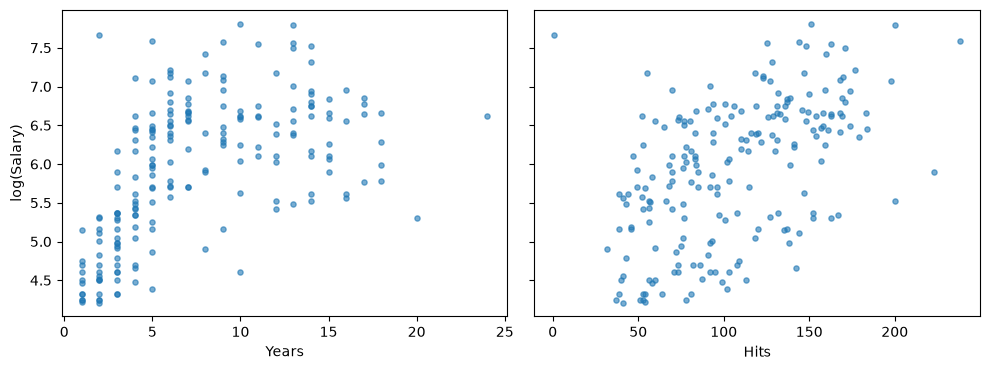

In [3]:
graficar_respuesta(X_ent, y_ent)

In [6]:
print(hitters["Salary"].skew(), y.skew())

1.5889673533412398 -0.1820065321570129


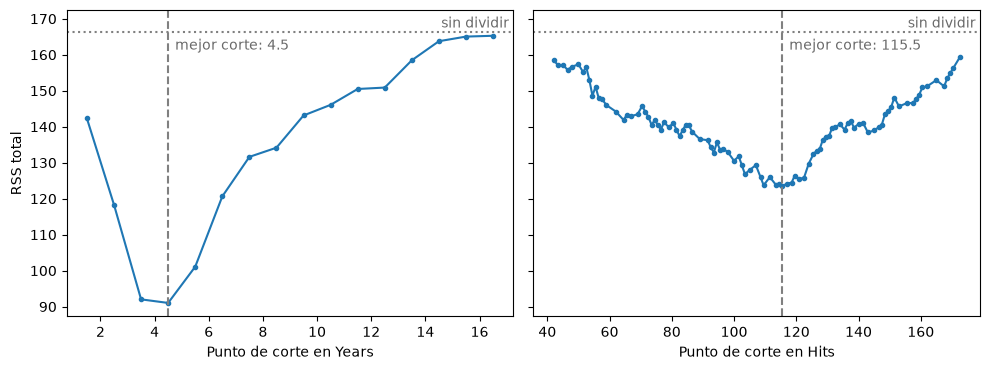

In [7]:
cortes = graficar_cortes(X_ent, y_ent, min_hoja = 10)

In [9]:
primer_corte = mejor_corte(X_ent, y_ent, min_hoja = 10)

print(primer_corte)

             cortes_admisibles  mejor_corte         RSS
Years                       16          4.5   91.028305
Hits                        97        115.5  123.477094
sin dividir                  0          NaN  166.402579


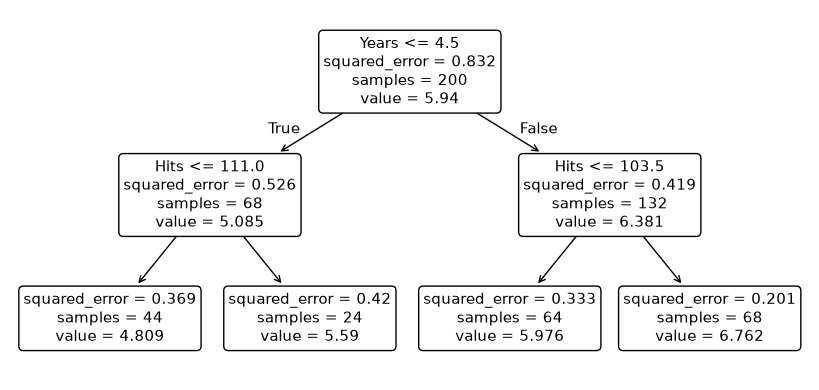

In [14]:
arbol = DecisionTreeRegressor(max_depth = 2, min_samples_split = 20, min_samples_leaf = 10, random_state = SEMILLA)

arbol.fit(X_ent, y_ent)
graficar_arbol(arbol)

In [16]:
hojas = tabla_hojas(arbol).assign(salario = lambda t: np.exp(t["prediccion"]))

print(hojas)

                            regla   n  prediccion     salario
hoja                                                         
2      Years <= 4.5 y Hits <= 111  44    4.809480  122.667769
3       Years <= 4.5 y Hits > 111  24    5.589615  267.632540
5     Years > 4.5 y Hits <= 103.5  64    5.976202  393.941252
6      Years > 4.5 y Hits > 103.5  68    6.761525  863.958764


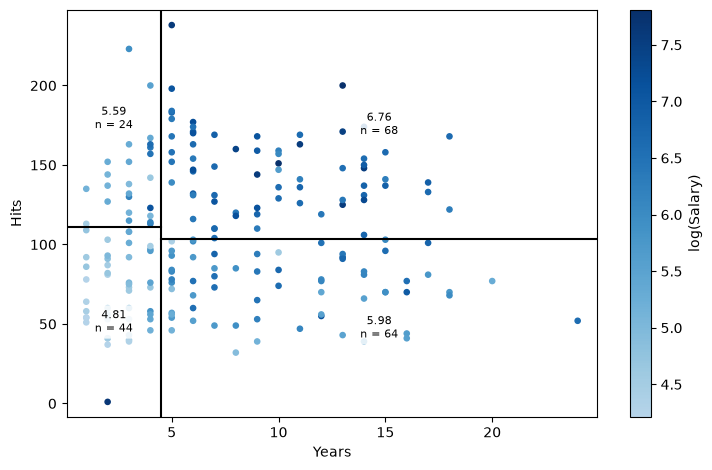

,regla,n,prediccion
hoja,,,
2,Years <= 4.5 y Hits <= 111,44,4.809480
3,Years <= 4.5 y Hits > 111,24,5.589615
5,Years > 4.5 y Hits <= 103.5,64,5.976202
6,Years > 4.5 y Hits > 103.5,68,6.761525


In [17]:
graficar_regiones(arbol, X_ent, color = y_ent)

In [ ]:
nuevos = pd.DataFrame({"Years": [3, 5, 7],
                        "Hits": [150, 90, 160]})


arbol.predict(nuevos)

pred_nuevos = predecir_con_ruta(arbol, nuevos).assign(salarios = lambda t: np.exp(t["prediccion"]))

In [20]:
print(pred_nuevos)

   Years  Hits  hoja                        regla   n  prediccion    salarios
0      3   150     3    Years <= 4.5 y Hits > 111  24    5.589615  267.632540
1      5    90     5  Years > 4.5 y Hits <= 103.5  64    5.976202  393.941252
2      7   160     6   Years > 4.5 y Hits > 103.5  68    6.761525  863.958764


In [26]:
lineal = LinearRegression()

errores = errores_regresion({"Media de entrenamiento": DummyRegressor(),
                            "Arbol": arbol,
                            "Regresion Lineal": lineal},
                            X_ent, y_ent, X_pru, y_pru)

In [27]:
print(errores)

                       entrenamiento                         prueba            \
                                 RSS       MSE      RMSE        RSS       MSE   
Media de entrenamiento    166.402579  0.832013  0.912147  40.795062  0.647541   
Arbol                      61.243446  0.306217  0.553369  24.872405  0.394800   
Regresion Lineal           78.232580  0.391163  0.625430  30.186675  0.479154   

                                  
                            RMSE  
Media de entrenamiento  0.804699  
Arbol                   0.628331  
Regresion Lineal        0.692209  


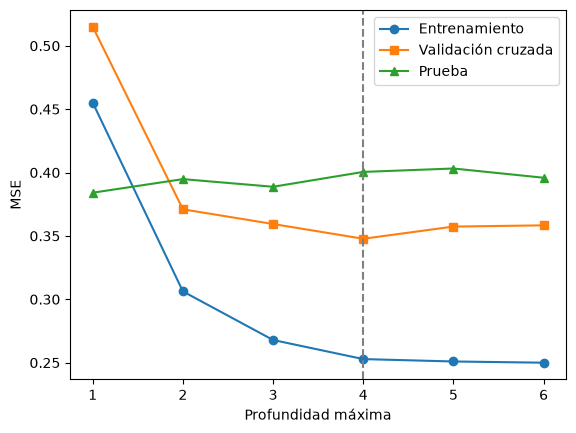

In [30]:
curva = curva_profundidad(DecisionTreeRegressor(min_samples_split = 20, min_samples_leaf = 10, random_state = 2026),
X_ent, y_ent, X_pru, y_pru, profundidades = range(1, 7), k = 10)

In [32]:
clase = pd.Series(np.where(hitters["Salary"] > 500, "Alto", "Bajo"), name = "clase")
c_ent, c_pru = clase.iloc[:200], clase.iloc[200:]

In [33]:
proporciones = pd.DataFrame({"entrenamiento": c_ent.value_counts(normalize = True),
                            "prueba": c_pru.value_counts(normalize = True)})

print(proporciones)

       entrenamiento    prueba
clase                         
Bajo            0.55  0.650794
Alto            0.45  0.349206


In [35]:
corte_gini = mejor_corte(X_ent, c_ent, min_hoja = 10, criterio = "gini")

print(corte_gini)

             cortes_admisibles  mejor_corte      Gini
Years                       16          5.5  0.357617
Hits                        97        115.5  0.359500
sin dividir                  0          NaN  0.495000


In [38]:
clasificador = DecisionTreeClassifier(criterion = "gini", max_depth = 2, min_samples_split = 20, min_samples_leaf = 10, random_state = SEMILLA)

clasificador.fit(X_ent, c_ent)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2026
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

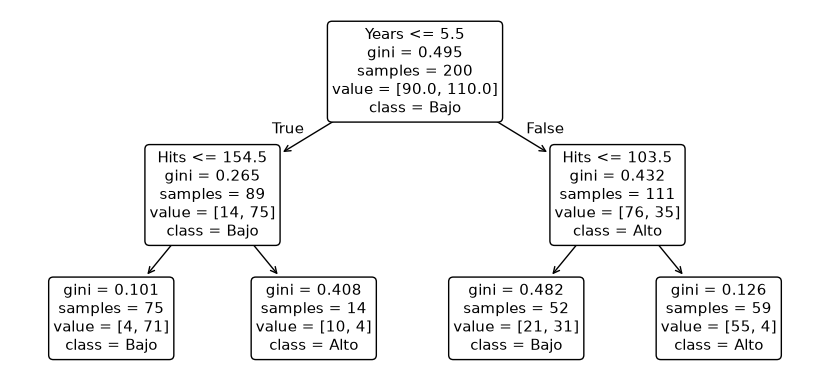

In [39]:
graficar_arbol(clasificador)

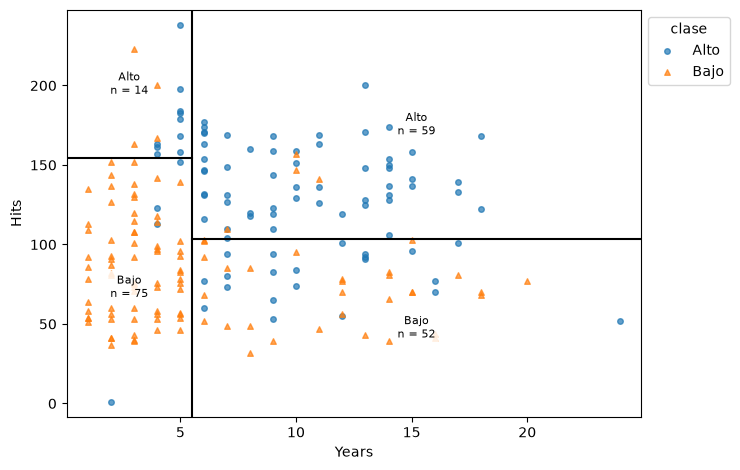

,regla,n,p_Alto,p_Bajo,clase
hoja,,,,,
2,Years <= 5.5 y Hits <= 154.5,75,0.053333,0.946667,Bajo
3,Years <= 5.5 y Hits > 154.5,14,0.714286,0.285714,Alto
5,Years > 5.5 y Hits <= 103.5,52,0.403846,0.596154,Bajo
6,Years > 5.5 y Hits > 103.5,59,0.932203,0.067797,Alto


In [40]:
graficar_regiones(clasificador, X_ent, color = c_ent)

In [42]:
predecir_con_ruta(clasificador, nuevos)

,Years,Hits,hoja,regla,n,p_Alto,p_Bajo,clase
0,3,150,2,Years <= 5.5 y Hits <= 154.5,75,0.053333,0.946667,Bajo
1,5,90,2,Years <= 5.5 y Hits <= 154.5,75,0.053333,0.946667,Bajo
2,7,160,6,Years > 5.5 y Hits > 103.5,59,0.932203,0.067797,Alto


In [51]:
logistica = make_pipeline(StandardScaler(), LogisticRegression(penalty = None))

metricas, matrices = metricas_clasificacion(
    {"Arbol de profundidad 2": clasificador,
    "Arbol de profundidad 1": clone(clasificador).set_params(max_depth = 1),
    "Regresion Logistica": logistica},
    X_ent, c_ent, X_pru, c_pru, positiva = "Alto"
)

/Users/torodriguezt/entornos/estadistica-II/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [52]:
print(metricas)

                             TCC     error  sensibilidad  especificidad
Arbol de profundidad 2  0.825397  0.174603      0.818182       0.829268
Arbol de profundidad 1  0.650794  0.349206      0.818182       0.560976
Regresion Logistica     0.793651  0.206349      0.727273       0.829268


In [53]:
for nombre, matriz in matrices.items():
    print(nombre, matriz, sep = "\n")

Arbol de profundidad 2
Predicho   Bajo  Alto
Observado            
Bajo         34     7
Alto          4    18
Arbol de profundidad 1
Predicho   Bajo  Alto
Observado            
Bajo         23    18
Alto          4    18
Regresion Logistica
Predicho   Bajo  Alto
Observado            
Bajo         34     7
Alto          6    16
